# Sesion 05-bi-ago-2026


In [59]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [60]:
sns.get_dataset_names()

['anagrams',
 'anscombe',
 'attention',
 'brain_networks',
 'car_crashes',
 'diamonds',
 'dots',
 'dowjones',
 'exercise',
 'flights',
 'fmri',
 'geyser',
 'glue',
 'healthexp',
 'iris',
 'mpg',
 'penguins',
 'planets',
 'seaice',
 'taxis',
 'tips',
 'titanic']

In [61]:
datos = sns.load_dataset("anscombe")
datos

,dataset,x,y
0,I,10.0,8.04
1,I,8.0,6.95
2,I,13.0,7.58
3,I,9.0,8.81
4,I,11.0,8.33
5,I,14.0,9.96
6,I,6.0,7.24
7,I,4.0,4.26
8,I,12.0,10.84
9,I,7.0,4.82


In [62]:
datos.groupby("dataset").agg(["mean", "std"]).round(2)

x          y      
        mean   std mean   std
dataset                      
I        9.0  3.32  7.5  2.03
II       9.0  3.32  7.5  2.03
III      9.0  3.32  7.5  2.03
IV       9.0  3.32  7.5  2.03

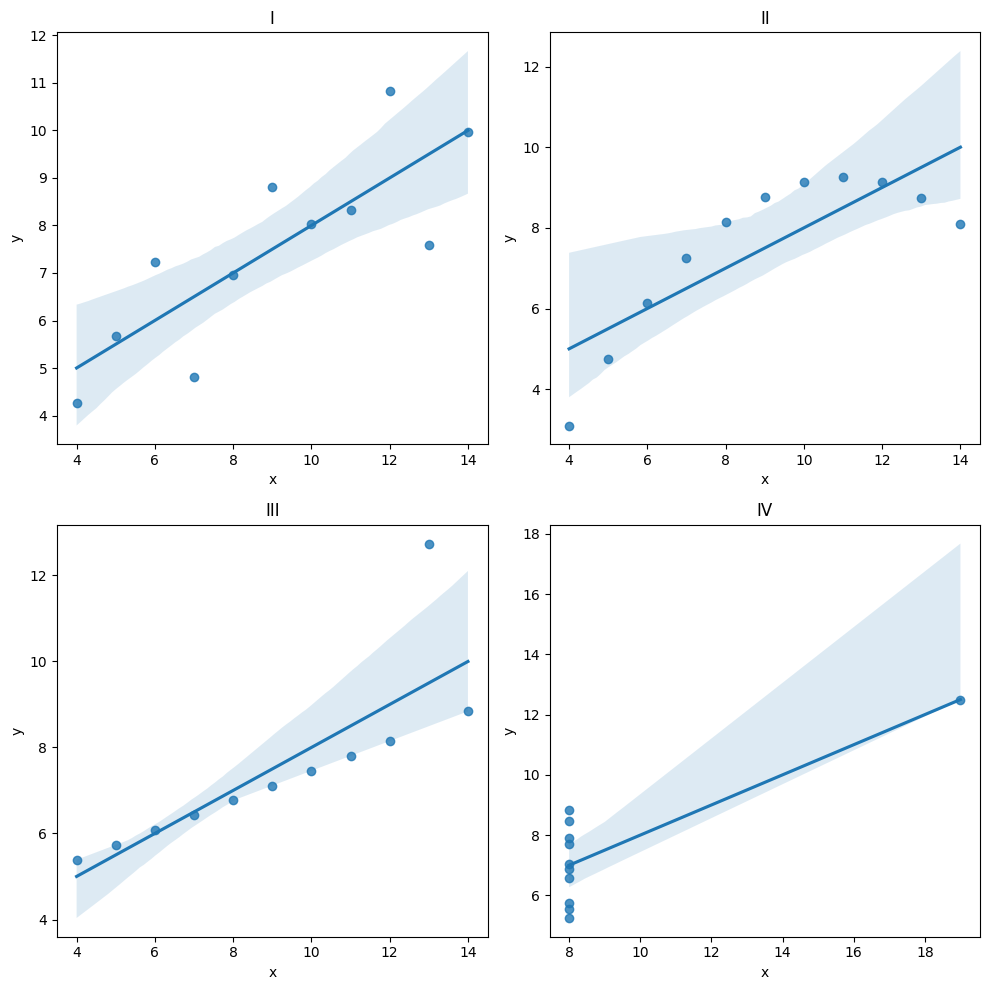

In [63]:
grupos = datos["dataset"].unique()

fig, axs = plt.subplots(2, 2, figsize=(10,10))
for grupo, ax in zip(grupos, axs.flatten()):
    sns.regplot(data=datos[datos.dataset == grupo], x="x", y="y", ax=ax)
    ax.set_title(grupo)

plt.tight_layout()
plt.show()


In [64]:
from sklearn.linear_model import LinearRegression
df = datos[datos.dataset == "I"]
X = df[["x"]]
y = df["y"]
reg = LinearRegression().fit(X,y)
print(reg.coef_.round(2), reg.intercept_.round(2))
print(reg.score(X,y))


[0.5] 3.0
0.6665424595087748


In [65]:
from sklearn.tree import DecisionTreeRegressor
reg = DecisionTreeRegressor(max_depth=2).fit(X,y)
reg.score(X,y)



0.762381820747566

# Market Basket Analysis

Similar a clustering.


In [66]:
# online retail dataset uci
url = "https://archive.ics.uci.edu/static/public/352/online+retail.zip"

In [67]:
# Descarga a colab

import os
os.system(f"wget {url}")


0

In [68]:
import zipfile

with zipfile.ZipFile("online+retail.zip", "r") as zip_ref:
    zip_ref.printdir()
    zip_ref.extractall()

File Name                                             Modified             Size
Online Retail.xlsx                             2023-05-22 15:20:26     23715344


In [69]:
archivo = pd.ExcelFile("Online Retail.xlsx")
archivo.sheet_names

['Online Retail']

In [70]:
df = archivo.parse()
df.shape

(541909, 8)

In [71]:
df

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
...,...,...,...,...,...,...,...,...
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France


In [72]:
# num. de articulos de la canasta 536365
df[df.InvoiceNo == 536365]


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
5,536365,22752,SET 7 BABUSHKA NESTING BOXES,2,2010-12-01 08:26:00,7.65,17850.0,United Kingdom
6,536365,21730,GLASS STAR FROSTED T-LIGHT HOLDER,6,2010-12-01 08:26:00,4.25,17850.0,United Kingdom


In [73]:
tickets = df.groupby(["InvoiceNo", "Description"])[["StockCode"]].count()


In [74]:
tickets = tickets.reset_index()
tickets.dropna(inplace=True)
tickets.dtypes


,0
InvoiceNo,object
Description,object
StockCode,int64


In [75]:
# compras int, concelaciones str
type(tickets.iloc[0,0])

int

In [76]:
# distinguiendo compras y cancelaciones
type(tickets.iloc[0,0]), type(tickets.iloc[-1,0])

(int, str)

In [77]:
tickets = tickets[~tickets.InvoiceNo.astype(str).str.startswith("C")]
tickets = tickets[tickets.Description != 20713]
tickets = tickets[~tickets.Description.astype(str).str.startswith("wrong")]
tickets = tickets[~tickets.Description.astype(str).str.startswith("wet")]
tickets.reset_index(inplace=True, drop=True)
tickets

,InvoiceNo,Description,StockCode
0,536365,CREAM CUPID HEARTS COAT HANGER,1
1,536365,GLASS STAR FROSTED T-LIGHT HOLDER,1
2,536365,KNITTED UNION FLAG HOT WATER BOTTLE,1
3,536365,RED WOOLLY HOTTIE WHITE HEART.,1
4,536365,SET 7 BABUSHKA NESTING BOXES,1
...,...,...,...
520412,581587,PLASTERS IN TIN STRONGMAN,1
520413,581587,SPACEBOY LUNCH BOX,1
520414,A563185,Adjust bad debt,1
520415,A563186,Adjust bad debt,1


In [78]:
!pip install mlxtend


In [79]:
from mlxtend.preprocessing import TransactionEncoder

In [80]:
tickets

,InvoiceNo,Description,StockCode
0,536365,CREAM CUPID HEARTS COAT HANGER,1
1,536365,GLASS STAR FROSTED T-LIGHT HOLDER,1
2,536365,KNITTED UNION FLAG HOT WATER BOTTLE,1
3,536365,RED WOOLLY HOTTIE WHITE HEART.,1
4,536365,SET 7 BABUSHKA NESTING BOXES,1
...,...,...,...
520412,581587,PLASTERS IN TIN STRONGMAN,1
520413,581587,SPACEBOY LUNCH BOX,1
520414,A563185,Adjust bad debt,1
520415,A563186,Adjust bad debt,1


In [82]:
# el df debe estar en formato largo

canasta = pd.pivot_table(tickets, index="InvoiceNo", columns="Description", values="StockCode", aggfunc="count")
canasta.sum(axis=1)

,0
InvoiceNo,
536365,7.0
536366,2.0
536367,12.0
536368,4.0
536369,1.0
...,...
581586,4.0
581587,15.0
A563185,1.0


In [85]:
# WHITE HANGING HEART T-LIGHT HOLDER	 2260
# filas en canasta -> numero total de tickets
# cols en canasta -> no. total de elementos distintos
canasta.shape


(20579, 4185)

$$
\large
\text{Support}=\frac{\text{Total number of times the item showed on one ticket}}{\text{Total number of tickets}}
$$

In [91]:
import warnings
from mlxtend.frequent_patterns import apriori

warnings.filterwarnings("ignore")

canasta = canasta.applymap(lambda x: 1 if x > 0 else 0)
apriori(canasta, min_support=0.8)


,support,itemsets


In [92]:
canasta.sum().sort_values()

,0
Description,
mix up with c,1
mouldy,1
"mouldy, thrown away.",1
"mouldy, unsaleable.",1
mystery! Only ever imported 1800,1
...,...
LUNCH BAG RED RETROSPOT,1564
PARTY BUNTING,1686
REGENCY CAKESTAND 3 TIER,1989


In [93]:
# WHITE HANGING HEART T-LIGHT HOLDER	 2260
# filas en canasta -> numero total de tickets
# cols en canasta -> no. total de elementos distintos
canasta.shape


(20579, 4185)

In [94]:
# proporcion de popularidad de un articulo
# support:
2260/20579


0.10982069099567521

In [ ]:
# aquellos articulos en el 10% (0.1) de canastas
apriori(canasta, min_support=0.1, use_colnames=True)


,support,itemsets
0,0.101657,(JUMBO BAG RED RETROSPOT)
1,0.109821,(WHITE HANGING HEART T-LIGHT HOLDER)


In [ ]:
apriori(canasta, min_support=0.025, use_colnames=True)


,support,itemsets
0,0.046407,(6 RIBBONS RUSTIC CHARM)
1,0.030031,(60 CAKE CASES VINTAGE CHRISTMAS)
2,0.040235,(60 TEATIME FAIRY CAKE CASES)
3,0.029885,(72 SWEETHEART FAIRY CAKE CASES)
4,0.047621,(ALARM CLOCK BAKELIKE GREEN)
...,...,...
204,0.026823,"(PAPER CHAIN KIT 50'S CHRISTMAS , PAPER CHAIN ..."
205,0.029107,"(ROSES REGENCY TEACUP AND SAUCER , PINK REGENC..."
206,0.025511,"(ROSES REGENCY TEACUP AND SAUCER , REGENCY CAK..."
207,0.026192,"(WOODEN FRAME ANTIQUE WHITE , WOODEN PICTURE F..."


In [ ]:
# lift, que tan independientes son parejas
#   si =1, no hay relacion entre ellos, si >1 hay mucha relacion, y es de forma nat.
#   si <1, aunque haya alta confidence, relaciones son azarosas


from mlxtend.frequent_patterns import association_rules
frequent_itemsets=apriori(canasta, min_support=0.025, use_colnames=True)
# confidence, Si A que seguridad tengo de -> B
association_rules(frequent_itemsets, metric="confidence", 
                  min_threshold=0.7, num_itemsets=len(df.index))


,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
0,(CHARLOTTE BAG PINK POLKADOT),(RED RETROSPOT CHARLOTTE BAG),0.036105,0.050245,0.025366,0.702557,13.982519,1.0,0.023552,3.193066,0.963260,0.415936,0.686821,0.603696
1,(GARDENERS KNEELING PAD CUP OF TEA ),(GARDENERS KNEELING PAD KEEP CALM ),0.036834,0.044366,0.026532,0.720317,16.235921,1.0,0.024898,3.416844,0.974295,0.485333,0.707332,0.659173
2,(PINK REGENCY TEACUP AND SAUCER),(GREEN REGENCY TEACUP AND SAUCER),0.037222,0.049322,0.030760,0.826371,16.754565,1.0,0.028924,5.475333,0.976669,0.551394,0.817363,0.725008
3,(ROSES REGENCY TEACUP AND SAUCER ),(GREEN REGENCY TEACUP AND SAUCER),0.051800,0.049322,0.037320,0.720450,14.607041,1.0,0.034765,3.400747,0.982430,0.584920,0.705947,0.738550
4,(GREEN REGENCY TEACUP AND SAUCER),(ROSES REGENCY TEACUP AND SAUCER ),0.049322,0.051800,0.037320,0.756650,14.607041,1.0,0.034765,3.896448,0.979869,0.584920,0.743356,0.738550
5,(PINK REGENCY TEACUP AND SAUCER),(ROSES REGENCY TEACUP AND SAUCER ),0.037222,0.051800,0.029107,0.781984,15.096112,1.0,0.027179,4.349227,0.969858,0.485807,0.770074,0.671949
6,"(ROSES REGENCY TEACUP AND SAUCER , PINK REGENC...",(GREEN REGENCY TEACUP AND SAUCER),0.029107,0.049322,0.026338,0.904841,18.345548,1.0,0.024902,9.990457,0.973837,0.505597,0.899904,0.719416
7,"(ROSES REGENCY TEACUP AND SAUCER , GREEN REGEN...",(PINK REGENCY TEACUP AND SAUCER),0.037320,0.037222,0.026338,0.705729,18.959792,1.0,0.024948,3.271740,0.983978,0.546371,0.694352,0.706650
8,"(GREEN REGENCY TEACUP AND SAUCER, PINK REGENCY...",(ROSES REGENCY TEACUP AND SAUCER ),0.030760,0.051800,0.026338,0.856240,16.529611,1.0,0.024744,6.595718,0.969318,0.468453,0.848386,0.682341
9,(PINK REGENCY TEACUP AND SAUCER),"(ROSES REGENCY TEACUP AND SAUCER , GREEN REGEN...",0.037222,0.037320,0.026338,0.707572,18.959792,1.0,0.024948,3.292023,0.983879,0.546371,0.696235,0.706650


In [100]:
association_rules(frequent_itemsets, metric="confidence", 
                  min_threshold=0.7, num_itemsets=len(df.index)
                  ).sort_values("antecedent support", ascending=False)


,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
3,(ROSES REGENCY TEACUP AND SAUCER ),(GREEN REGENCY TEACUP AND SAUCER),0.051800,0.049322,0.037320,0.720450,14.607041,1.0,0.034765,3.400747,0.982430,0.584920,0.705947,0.738550
4,(GREEN REGENCY TEACUP AND SAUCER),(ROSES REGENCY TEACUP AND SAUCER ),0.049322,0.051800,0.037320,0.756650,14.607041,1.0,0.034765,3.896448,0.979869,0.584920,0.743356,0.738550
7,"(ROSES REGENCY TEACUP AND SAUCER , GREEN REGEN...",(PINK REGENCY TEACUP AND SAUCER),0.037320,0.037222,0.026338,0.705729,18.959792,1.0,0.024948,3.271740,0.983978,0.546371,0.694352,0.706650
9,(PINK REGENCY TEACUP AND SAUCER),"(ROSES REGENCY TEACUP AND SAUCER , GREEN REGEN...",0.037222,0.037320,0.026338,0.707572,18.959792,1.0,0.024948,3.292023,0.983879,0.546371,0.696235,0.706650
5,(PINK REGENCY TEACUP AND SAUCER),(ROSES REGENCY TEACUP AND SAUCER ),0.037222,0.051800,0.029107,0.781984,15.096112,1.0,0.027179,4.349227,0.969858,0.485807,0.770074,0.671949
2,(PINK REGENCY TEACUP AND SAUCER),(GREEN REGENCY TEACUP AND SAUCER),0.037222,0.049322,0.030760,0.826371,16.754565,1.0,0.028924,5.475333,0.976669,0.551394,0.817363,0.725008
1,(GARDENERS KNEELING PAD CUP OF TEA ),(GARDENERS KNEELING PAD KEEP CALM ),0.036834,0.044366,0.026532,0.720317,16.235921,1.0,0.024898,3.416844,0.974295,0.485333,0.707332,0.659173
0,(CHARLOTTE BAG PINK POLKADOT),(RED RETROSPOT CHARLOTTE BAG),0.036105,0.050245,0.025366,0.702557,13.982519,1.0,0.023552,3.193066,0.963260,0.415936,0.686821,0.603696
8,"(GREEN REGENCY TEACUP AND SAUCER, PINK REGENCY...",(ROSES REGENCY TEACUP AND SAUCER ),0.030760,0.051800,0.026338,0.856240,16.529611,1.0,0.024744,6.595718,0.969318,0.468453,0.848386,0.682341
6,"(ROSES REGENCY TEACUP AND SAUCER , PINK REGENC...",(GREEN REGENCY TEACUP AND SAUCER),0.029107,0.049322,0.026338,0.904841,18.345548,1.0,0.024902,9.990457,0.973837,0.505597,0.899904,0.719416
